In [32]:
import pandas as pd

df = pd.read_csv("final_validated_dataset.csv")
print("Dataset size:", df.shape)
display(df.head())
display(df.dtypes)
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Loan status values:")
print(df["loan_status"].value_counts())

Dataset size: (32416, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,4.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


person_age                    float64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Duplicate rows: 0
Loan status values:
loan_status
0    25327
1     7089
Name: count, dtype: int64


In [33]:
print("Total records:", len(df))
print(df["loan_status"].value_counts().sort_index())

Total records: 32416
loan_status
0    25327
1     7089
Name: count, dtype: int64


In [34]:
target_summary = pd.DataFrame({
    "count": df["loan_status"].value_counts().sort_index(),
    "percentage": (
        df["loan_status"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(target_summary)

,count,percentage
loan_status,,
0,25327,78.13
1,7089,21.87


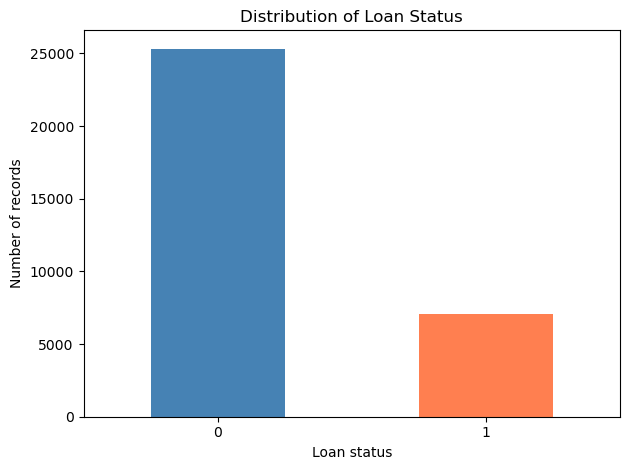

In [35]:
import matplotlib.pyplot as plt

target_summary["count"].plot(kind="bar", color=["steelblue", "coral"])

plt.title("Distribution of Loan Status")
plt.xlabel("Loan status")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="loan_status")
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 25932
Test rows: 6484


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

one_hot_columns = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

ordinal_columns = ["loan_grade"]

numeric_columns = [
    column for column in X.columns
    if column not in one_hot_columns + ordinal_columns
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "one_hot",
            OneHotEncoder(handle_unknown="ignore"),
            one_hot_columns
        ),
        (
            "ordinal",
            OrdinalEncoder(
                categories=[["A", "B", "C", "D", "E", "F", "G"]],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            ordinal_columns
        ),
        ("numeric", "passthrough", numeric_columns)
    ],
    verbose_feature_names_out=False
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)
print("Encoded columns:", preprocessor.get_feature_names_out())

Encoded training shape: (25932, 20)
Encoded test shape: (6484, 20)
Encoded columns: ['person_home_ownership_MORTGAGE' 'person_home_ownership_OTHER'
 'person_home_ownership_OWN' 'person_home_ownership_RENT'
 'loan_intent_DEBTCONSOLIDATION' 'loan_intent_EDUCATION'
 'loan_intent_HOMEIMPROVEMENT' 'loan_intent_MEDICAL'
 'loan_intent_PERSONAL' 'loan_intent_VENTURE'
 'cb_person_default_on_file_N' 'cb_person_default_on_file_Y' 'loan_grade'
 'person_age' 'person_income' 'person_emp_length' 'loan_amnt'
 'loan_int_rate' 'loan_percent_income' 'cb_person_cred_hist_length']


In [38]:
X_train_encoded = preprocessor.fit_transform(X_train)

In [39]:
import joblib

joblib.dump(preprocessor, "step3_preprocessor.joblib")

['step3_preprocessor.joblib']

In [40]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,27.730102,6.609164e+04,4.761538,9593.845632,11.020159,0.218688,0.170250,5.811297
std,6.210006,6.201558e+04,3.983588,6322.730241,3.213380,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,7.880000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,6.000000e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [41]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

In [42]:
group_summary.to_csv("outputs/step4_median_by_loan_status.csv")

In [43]:
df.describe().to_csv("outputs/step4_descriptive_statistics.csv")

In [44]:
from scipy.stats import chi2_contingency

home_table = pd.crosstab(
    df["person_home_ownership"],
    df["loan_status"]
)

display(home_table)

chi2, p_value, dof, expected = chi2_contingency(home_table)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Smallest expected count:", expected.min())

home_table.to_csv("outputs/step4_home_ownership_counts.csv")

loan_status,0,1
person_home_ownership,,
MORTGAGE,11682,1687
OTHER,73,33
OWN,2371,192
RENT,11201,5177


Chi-square statistic: 1894.3526733955891
p-value: 0.0
Smallest expected count: 23.18096001974334


In [46]:
home_status_1_rate = (
    home_table[1] / home_table.sum(axis=1) * 100
).round(2)

display(home_status_1_rate)
home_status_1_rate.to_csv(
    "outputs/step4_home_ownership_status1_rates.csv",
    header=["status_1_percentage"]
)

person_home_ownership
MORTGAGE    12.62
OTHER       31.13
OWN          7.49
RENT        31.61
dtype: float64

In [47]:
correlations = (
    df.corr(numeric_only=True)["loan_status"]
      .drop("loan_status")
      .sort_values()
)

display(correlations)
correlations.to_csv("outputs/step4_correlations.csv",
                    header=["correlation_with_loan_status"])

person_income                -0.145005
person_emp_length            -0.085984
person_age                   -0.021785
cb_person_cred_hist_length   -0.016498
loan_amnt                     0.105736
loan_int_rate                 0.334147
loan_percent_income           0.379697
Name: loan_status, dtype: float64

In [48]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_features = [
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

results = []

for feature in categorical_features:
    table = pd.crosstab(df[feature], df["loan_status"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    status_1_rate = (table[1] / table.sum(axis=1) * 100).round(2)

    print("\nFeature:", feature)
    display(pd.DataFrame({
        "status_0": table[0],
        "status_1": table[1],
        "status_1_percentage": status_1_rate
    }))
    print("Chi-square statistic:", chi2)
    print("p-value:", p_value)
    print("Smallest expected count:", expected.min())

    results.append({
        "feature": feature,
        "chi_square": chi2,
        "p_value": p_value,
        "smallest_expected_count": expected.min()
    })

chi_square_results = pd.DataFrame(results)
chi_square_results.to_csv(
    "outputs/step4_chi_square_results.csv", index=False
)


Feature: loan_intent


,status_0,status_1,status_1_percentage
loan_intent,,,
DEBTCONSOLIDATION,3701,1488,28.68
EDUCATION,5305,1106,17.25
HOMEIMPROVEMENT,2654,940,26.15
MEDICAL,4425,1617,26.76
PERSONAL,4404,1094,19.90
VENTURE,4838,844,14.85


Chi-square statistic: 520.1813803410885
p-value: 3.5123818980037483e-110
Smallest expected count: 785.965757650543

Feature: loan_grade


,status_0,status_1,status_1_percentage
loan_grade,,,
A,9637,1066,9.96
B,8692,1695,16.32
C,5102,1336,20.75
D,1482,2138,59.06
E,342,621,64.49
F,71,170,70.54
G,1,63,98.44


Chi-square statistic: 5588.326418998944
p-value: 0.0
Smallest expected count: 13.996051332675222

Feature: cb_person_default_on_file


,status_0,status_1,status_1_percentage
cb_person_default_on_file,,,
N,21767,4919,18.43
Y,3560,2170,37.87


Chi-square statistic: 1041.973789110078
p-value: 1.3516442792486318e-228
Smallest expected count: 1253.0839708785784


In [49]:
from scipy.stats import ttest_ind
import pandas as pd

numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

test_results = []

for feature in numeric_features:
    group_0 = df.loc[df["loan_status"] == 0, feature].dropna()
    group_1 = df.loc[df["loan_status"] == 1, feature].dropna()

    test = ttest_ind(group_0, group_1, equal_var=False)

    test_results.append({
        "feature": feature,
        "mean_status_0": group_0.mean(),
        "mean_status_1": group_1.mean(),
        "p_value": test.pvalue
    })

t_test_results = pd.DataFrame(test_results)
display(t_test_results)

t_test_results.to_csv("outputs/step4_t_test_results.csv", index=False)

,feature,mean_status_0,mean_status_1,p_value
0,person_age,27.801674,27.474397,9.771256e-05
1,person_income,70849.122794,49094.497955,6.044839e-278
2,person_emp_length,4.942749,4.114120,2.092752e-57
3,loan_amnt,9240.155763,10857.479898,6.920493e-67
4,loan_int_rate,10.452100,13.049673,0.000000e+00
5,loan_percent_income,0.148794,0.246906,0.000000e+00
6,cb_person_cred_hist_length,5.846725,5.684723,3.221191e-03


In [50]:
import pandas as pd
import numpy as np

woe_data = X_train[["loan_percent_income"]].copy()
woe_data["loan_status"] = y_train

woe_data["income_ratio_bin"] = pd.qcut(
    woe_data["loan_percent_income"],
    q=5,
    duplicates="drop"
)

display(
    woe_data.groupby("income_ratio_bin", observed=True)["loan_status"]
            .agg(["count", "mean"])
)

,count,mean
income_ratio_bin,,
"(-0.001, 0.08]",5962,0.114559
"(0.08, 0.12]",4472,0.123658
"(0.12, 0.18]",5809,0.151833
"(0.18, 0.25]",4660,0.191631
"(0.25, 0.83]",5029,0.528932


In [51]:
counts = pd.crosstab(
    woe_data["income_ratio_bin"],
    woe_data["loan_status"]
).reindex(columns=[0, 1], fill_value=0)

counts.columns = ["good_count", "bad_count"]
display(counts)

,good_count,bad_count
income_ratio_bin,,
"(-0.001, 0.08]",5279,683
"(0.08, 0.12]",3919,553
"(0.12, 0.18]",4927,882
"(0.18, 0.25]",3767,893
"(0.25, 0.83]",2369,2660


In [52]:
# Add 0.5 to every count so a zero-count group will not cause division by zero.
smoothed = counts + 0.5

good_share = smoothed["good_count"] / smoothed["good_count"].sum()
bad_share = smoothed["bad_count"] / smoothed["bad_count"].sum()

counts["good_share"] = good_share
counts["bad_share"] = bad_share
counts["WoE"] = np.log(good_share / bad_share)
counts["IV_contribution"] = (
    (good_share - bad_share) * counts["WoE"]
)

display(counts)
print("Total IV:", counts["IV_contribution"].sum())

counts.to_csv("outputs/step5_loan_percent_income_woe.csv")

,good_count,bad_count,good_share,bad_share,WoE,IV_contribution
income_ratio_bin,,,,,,
"(-0.001, 0.08]",5279,683,0.260542,0.120472,0.771345,0.108042
"(0.08, 0.12]",3919,553,0.193427,0.097559,0.684443,0.065616
"(0.12, 0.18]",4927,882,0.243171,0.155548,0.446813,0.039151
"(0.18, 0.25]",3767,893,0.185925,0.157487,0.166006,0.004721
"(0.25, 0.83]",2369,2660,0.116934,0.468935,-1.388850,0.488875


Total IV: 0.706406049931219


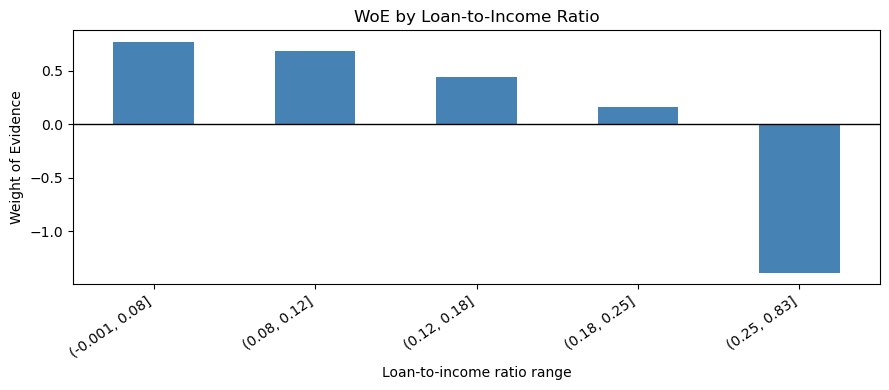

In [53]:
import matplotlib.pyplot as plt

ax = counts["WoE"].plot(kind="bar", figsize=(9, 4), color="steelblue")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("WoE by Loan-to-Income Ratio")
ax.set_xlabel("Loan-to-income ratio range")
ax.set_ylabel("Weight of Evidence")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    "outputs/step5_loan_percent_income_woe.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [54]:
grade_data = X_train[["loan_grade"]].copy()
grade_data["loan_status"] = y_train

grade_counts = pd.crosstab(
    grade_data["loan_grade"],
    grade_data["loan_status"]
).reindex(index=list("ABCDEFG"), columns=[0, 1], fill_value=0)

grade_counts.columns = ["good_count", "bad_count"]

smoothed = grade_counts + 0.5
good_share = smoothed["good_count"] / smoothed["good_count"].sum()
bad_share = smoothed["bad_count"] / smoothed["bad_count"].sum()

grade_counts["good_share"] = good_share
grade_counts["bad_share"] = bad_share
grade_counts["WoE"] = np.log(good_share / bad_share)
grade_counts["IV_contribution"] = (
    good_share - bad_share
) * grade_counts["WoE"]

display(grade_counts)
print("Loan grade Total IV:", grade_counts["IV_contribution"].sum())

grade_counts.to_csv("outputs/step5_loan_grade_woe.csv")

,good_count,bad_count,good_share,bad_share,WoE,IV_contribution
loan_grade,,,,,,
A,7727,857,0.381332,0.151115,0.925631,0.213096
B,6931,1354,0.342051,0.238699,0.359756,0.037181
C,4092,1081,0.201954,0.190589,0.057919,0.000658
D,1184,1705,0.058452,0.300555,-1.637426,0.396426
E,274,491,0.013546,0.086616,-1.855399,0.135573
F,52,136,0.002591,0.024055,-2.228400,0.047831
G,1,47,0.000074,0.008371,-4.728153,0.039228


Loan grade Total IV: 0.8699946031800238


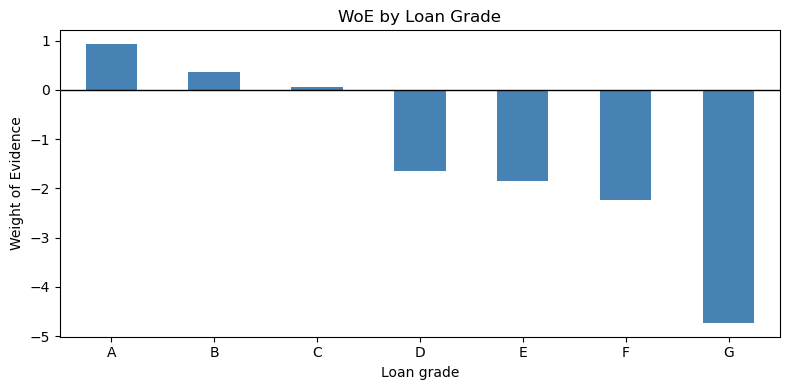

In [55]:
ax = grade_counts["WoE"].plot(
    kind="bar", figsize=(8, 4), color="steelblue"
)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("WoE by Loan Grade")
ax.set_xlabel("Loan grade")
ax.set_ylabel("Weight of Evidence")

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/step5_loan_grade_woe.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

def calculate_woe(feature):
    data = X_train[[feature]].copy()
    data["loan_status"] = y_train

    # Numeric features need ranges; categorical features already have groups.
    if pd.api.types.is_numeric_dtype(data[feature]):
        groups = pd.qcut(data[feature], q=5, duplicates="drop")
    else:
        groups = data[feature]

    groups = groups.astype(str).fillna("Missing")
    table = pd.crosstab(groups, data["loan_status"])
    table = table.reindex(columns=[0, 1], fill_value=0)
    table.columns = ["good_count", "bad_count"]

    smoothed = table[["good_count", "bad_count"]] + 0.5
    good_share = smoothed["good_count"] / smoothed["good_count"].sum()
    bad_share = smoothed["bad_count"] / smoothed["bad_count"].sum()

    table["good_share"] = good_share
    table["bad_share"] = bad_share
    table["WoE"] = np.log(good_share / bad_share)
    table["IV_contribution"] = (
        good_share - bad_share
    ) * table["WoE"]

    total_iv = table["IV_contribution"].sum()

    table.to_csv(output_dir / f"step5_{feature}_woe.csv")

    ax = table["WoE"].plot(kind="bar", figsize=(9, 4))
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"WoE: {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Weight of Evidence")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(
        output_dir / f"step5_{feature}_woe.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.close()

    return total_iv

In [57]:
remaining_features = [
    "person_age",
    "person_income",
    "person_home_ownership",
    "person_emp_length",
    "loan_intent",
    "loan_amnt",
    "loan_int_rate",
    "cb_person_default_on_file",
    "cb_person_cred_hist_length"
]

iv_results = pd.DataFrame([
    {"feature": feature, "IV": calculate_woe(feature)}
    for feature in remaining_features
]).sort_values("IV", ascending=False)

display(iv_results)
iv_results.to_csv("outputs/step5_remaining_iv_summary.csv", index=False)

,feature,IV
6,loan_int_rate,0.664960
1,person_income,0.447192
2,person_home_ownership,0.383127
7,cb_person_default_on_file,0.165072
4,loan_intent,0.092498
5,loan_amnt,0.077343
3,person_emp_length,0.048854
0,person_age,0.007374
8,cb_person_cred_hist_length,0.004386


In [58]:
all_iv = pd.concat([
    iv_results,
    pd.DataFrame([
        {
            "feature": "loan_grade",
            "IV": grade_counts["IV_contribution"].sum()
        },
        {
            "feature": "loan_percent_income",
            "IV": counts["IV_contribution"].sum()
        }
    ])
], ignore_index=True).sort_values("IV", ascending=False)

display(all_iv)
all_iv.to_csv("outputs/step5_all_feature_iv_summary.csv", index=False)

,feature,IV
9,loan_grade,0.869995
10,loan_percent_income,0.706406
0,loan_int_rate,0.664960
1,person_income,0.447192
2,person_home_ownership,0.383127
3,cb_person_default_on_file,0.165072
4,loan_intent,0.092498
5,loan_amnt,0.077343
6,person_emp_length,0.048854
7,person_age,0.007374
